# AlexNet similarity check for the interference design

This notebook checks whether the stimulus set can support the planned EEG–DNN comparison:

- **High interference (HI):** 15 concepts × 10 exemplars = 150 images
- **Low interference (LI):** 150 other concepts × 1 exemplar = 150 images

It answers three questions:

1. **How similar are exemplars of the same concept**, in early vs. late AlexNet layers? Late layers *should* see them as similar (that is what creates interference). Early layers should still show clear differences, otherwise there is no perceptual detail the brain could use to tell them apart.
2. **Are early and late layers separable?** If the early-layer and late-layer RDMs are very highly correlated, no EEG analysis can tell "perceptual" from "categorical" apart.
3. **Design simulation:** for many random HI/LI splits, how different are the two image sets in DNN space, and does matching between-concept pairs on DNN distance remove that difference?

**Run from this folder** (`Stimuli/Selection20_resized`, next to `stimuli_list.csv`). The first run downloads the AlexNet weights (~230 MB) to `~/.cache/torch`. CSV tables go to `alexnet_tables/` (small, kept in git); RDMs and figures go to `alexnet_outputs/` (git-ignored).

Requirements: `pip install torch torchvision pandas scipy matplotlib`

In [14]:
# If needed, uncomment and run once:
# %pip install torch torchvision pandas scipy matplotlib

## 1. Setup

In [15]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import alexnet, AlexNet_Weights

STIM_DIR = Path.cwd()                      # notebook lives next to stimuli_list.csv
LIST_CSV = STIM_DIR / 'stimuli_list.csv'
OUT_DIR = STIM_DIR / 'alexnet_outputs'
OUT_DIR.mkdir(exist_ok=True)
TABLE_DIR = STIM_DIR / 'alexnet_tables'
TABLE_DIR.mkdir(exist_ok=True)
assert LIST_CSV.exists(), f'stimuli_list.csv not found in {STIM_DIR} - open the notebook from Stimuli/Selection20_resized'

# Design parameters
N_HI_CONCEPTS = 15
N_HI_EXEMPLARS = 10
N_LI_CONCEPTS = 150
N_SIMULATIONS = 200
SEED = 1

# Which layers count as "early" (perceptual) and "late" (categorical) in the summary analyses
EARLY, LATE = 'conv2', 'fc7'

if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')           # Apple-silicon GPU
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print('Device:', DEVICE)

Device: mps


In [16]:
stim = pd.read_csv(LIST_CSV)
stim = stim.reset_index(drop=True)
concepts = stim['subcategory'].values
categories = stim['category'].values
concept_names = np.array(sorted(stim['subcategory'].unique()))
print(f'{len(stim)} images, {len(concept_names)} concepts, {stim.category.nunique()} categories')
missing = [p for p in stim['path'] if not (STIM_DIR / p).exists()]
print('Missing image files:', len(missing))
stim.groupby('category').subcategory.nunique()

3300 images, 165 concepts, 9 categories
Missing image files: 0


category
Animals                        24
Clothing_Accessories           22
Electronic_device_Appliance    17
Fruit_Veggies                  20
Furniture_Home_decor           18
Kitchenware                    11
Musical_Instruments            13
Tools                          16
Vehicles                       24
Name: subcategory, dtype: int64

## 2. Extract AlexNet features

Standard torchvision AlexNet (ImageNet-trained). Images are resized to 224 × 224 **without cropping**, so objects near the edge are kept.

Activations are taken after each ReLU (`conv1`–`conv5`, `fc6`, `fc7`) plus the `fc8` logits. To keep memory manageable, convolutional maps are average-pooled to a smaller grid (`conv1` 55→27, `conv2` 27→13; `conv3`–`conv5` are already 13 × 13), which keeps the spatial layout. Features are only held in memory; the saved output is the RDMs.

In [17]:
weights = AlexNet_Weights.IMAGENET1K_V1
model = alexnet(weights=weights).eval().to(DEVICE)

# (module, name, pooled spatial size or None)
LAYERS = [
    (model.features[1],   'conv1', 27),
    (model.features[4],   'conv2', 13),
    (model.features[7],   'conv3', 13),
    (model.features[9],   'conv4', 13),
    (model.features[11],  'conv5', 13),
    (model.classifier[2], 'fc6',   None),
    (model.classifier[5], 'fc7',   None),
    (model.classifier[6], 'fc8',   None),
]
LAYER_NAMES = [n for _, n, _ in LAYERS]

_acts = {}
def make_hook(name, pool):
    def hook(module, inp, out):
        a = out.detach().float().cpu()   # pool on CPU (MPS cannot pool to non-divisible sizes)
        if pool is not None and a.shape[-1] != pool:
            a = F.adaptive_avg_pool2d(a, pool)
        _acts[name] = a.flatten(1)
    return hook
handles = [m.register_forward_hook(make_hook(n, p)) for m, n, p in LAYERS]

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [18]:
RDM_FILE = OUT_DIR / 'alexnet_rdms.npz'
BATCH = 50

def rdm_from_features(X):
    # 1 - Pearson correlation between images (rows)
    X = torch.as_tensor(X, dtype=torch.float32)
    X = X - X.mean(1, keepdim=True)
    X = X / (X.norm(dim=1, keepdim=True) + 1e-8)
    return (1 - X @ X.T).clamp(min=0).numpy()

if RDM_FILE.exists():
    data = np.load(RDM_FILE, allow_pickle=True)
    assert list(data['image_id']) == list(stim['image_id']), 'Cached RDMs do not match stimuli_list.csv - delete alexnet_rdms.npz'
    RDMS = {n: data[n].astype(np.float32) for n in LAYER_NAMES}
    print('Loaded cached RDMs from', RDM_FILE)
else:
    feats = {n: [] for n in LAYER_NAMES}
    t0 = time.time()
    with torch.no_grad():
        for start in range(0, len(stim), BATCH):
            paths = stim['path'].iloc[start:start + BATCH]
            x = torch.stack([preprocess(Image.open(STIM_DIR / p).convert('RGB')) for p in paths]).to(DEVICE)
            model(x)
            for n in LAYER_NAMES:
                feats[n].append(_acts[n].numpy().astype(np.float16))
            if start % 500 == 0:
                print(f'{start:5d}/{len(stim)}  ({time.time() - t0:.0f} s)')
    RDMS = {}
    for n in LAYER_NAMES:
        X = np.concatenate(feats[n])
        print(f'{n}: {X.shape[1]} features')
        RDMS[n] = rdm_from_features(X)
        feats[n] = None
    np.savez_compressed(RDM_FILE, image_id=stim['image_id'].values,
                        **{n: RDMS[n].astype(np.float16) for n in LAYER_NAMES})
    print(f'Done in {time.time() - t0:.0f} s, saved to {RDM_FILE}')

for h in handles:
    h.remove()

    0/3300  (0 s)
  500/3300  (4 s)
 1000/3300  (7 s)
 1500/3300  (10 s)
 2000/3300  (12 s)
 2500/3300  (15 s)
 3000/3300  (17 s)
conv1: 46656 features
conv2: 32448 features
conv3: 64896 features
conv4: 43264 features
conv5: 43264 features
fc6: 4096 features
fc7: 4096 features
fc8: 1000 features
Done in 38 s, saved to /Users/ekindogailkel/Memory_Interference_Experiment/Stimuli/Selection20_resized/alexnet_outputs/alexnet_rdms.npz


## 3. Within-concept vs. between-concept distances

Pairs of images are split into three types:
- **same concept** (bee–bee)
- **same category, different concept** (bee–fox)
- **different category** (bee–hammer)

Distances are 1 − Pearson r, so the absolute scale differs between layers. The **separation index** puts layers on a common scale: how far within-concept pairs sit below different-concept pairs, in standard deviations of the different-concept distribution. Large = exemplars look alike relative to other concepts.

In [19]:
N = len(stim)
iu = np.triu_indices(N, k=1)
same_concept = (concepts[iu[0]] == concepts[iu[1]])
same_category = (categories[iu[0]] == categories[iu[1]])
pair_type = np.where(same_concept, 'same concept',
             np.where(same_category, 'same category', 'different category'))
PAIR_TYPES = ['same concept', 'same category', 'different category']

vec = {n: RDMS[n][iu] for n in LAYER_NAMES}   # upper-triangle vectors

rows = []
for n in LAYER_NAMES:
    v = vec[n]
    between = v[~same_concept]
    sep = (between.mean() - v[same_concept].mean()) / between.std()
    r = {'layer': n, 'separation_index': sep}
    for t in PAIR_TYPES:
        r[f'mean dist: {t}'] = v[pair_type == t].mean()
    rows.append(r)
layer_summary = pd.DataFrame(rows).set_index('layer')
layer_summary.to_csv(TABLE_DIR / 'layer_summary.csv')
layer_summary.round(3)

,separation_index,mean dist: same concept,mean dist: same category,mean dist: different category
layer,,,,
conv1,0.877,0.809,0.858,0.885
conv2,1.473,0.856,0.910,0.935
conv3,1.737,0.883,0.921,0.936
conv4,2.035,0.884,0.932,0.953
conv5,3.056,0.873,0.955,0.986
fc6,3.585,0.726,0.924,0.986
fc7,4.365,0.717,0.935,0.993
fc8,1.704,0.330,0.573,0.830


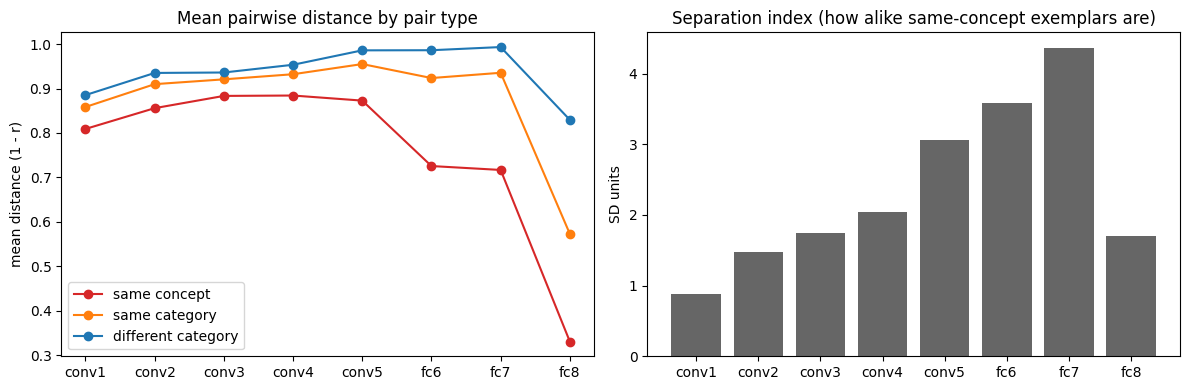

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(LAYER_NAMES))
for t, c in zip(PAIR_TYPES, ['C3', 'C1', 'C0']):
    axes[0].plot(x, layer_summary[f'mean dist: {t}'], 'o-', color=c, label=t)
axes[0].set_xticks(x, LAYER_NAMES); axes[0].set_ylabel('mean distance (1 - r)')
axes[0].set_title('Mean pairwise distance by pair type'); axes[0].legend()
axes[1].bar(x, layer_summary['separation_index'], color='0.4')
axes[1].set_xticks(x, LAYER_NAMES); axes[1].set_ylabel('SD units')
axes[1].set_title('Separation index (how alike same-concept exemplars are)')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig1_layer_distances.png', dpi=150); plt.show()

### Per concept

For every concept: mean within-concept distance in the early and late layer, each as a z-score relative to that layer's different-concept distances (negative = exemplars more alike than random different-concept pairs).

Concepts in the **lower-left** of the scatter are alike in *both* layers, i.e. the exemplars offer little perceptual variation. Those are the ones to look at before choosing the 15 HI concepts.

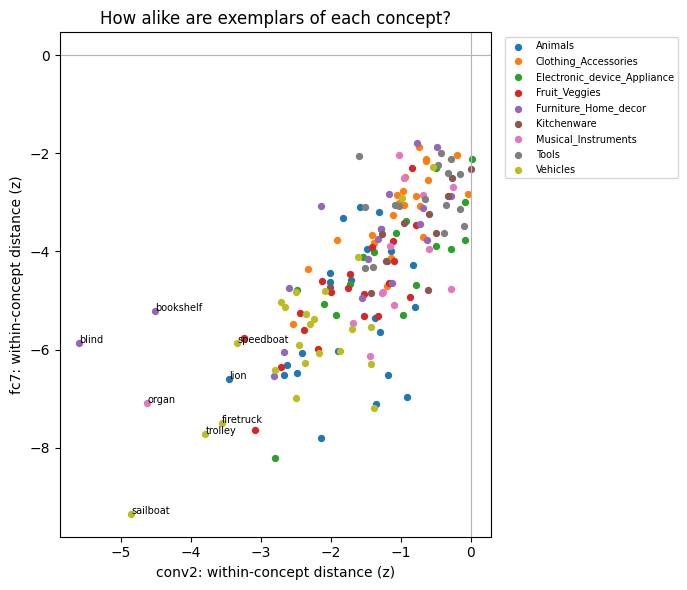

Concepts whose exemplars are most alike in conv2


,conv2_within_z,fc7_within_z,category
blind,-5.60,-5.86,Furniture_Home_decor
sailboat,-4.86,-9.35,Vehicles
organ,-4.63,-7.08,Musical_Instruments
bookshelf,-4.52,-5.21,Furniture_Home_decor
trolley,-3.79,-7.72,Vehicles
firetruck,-3.56,-7.49,Vehicles
lion,-3.46,-6.60,Animals
speedboat,-3.34,-5.87,Vehicles
broccoli,-3.25,-5.76,Fruit_Veggies
cauliflower,-3.08,-7.63,Fruit_Veggies


In [21]:
def concept_table(layer):
    D = RDMS[layer]
    v = vec[layer][~same_concept]
    mu, sd = v.mean(), v.std()
    out = {}
    for c in concept_names:
        idx = np.where(concepts == c)[0]
        sub = D[np.ix_(idx, idx)][np.triu_indices(len(idx), 1)]
        out[c] = (sub.mean() - mu) / sd
    return pd.Series(out)

ct = pd.DataFrame({f'{EARLY}_within_z': concept_table(EARLY),
                   f'{LATE}_within_z': concept_table(LATE)})
ct['category'] = stim.groupby('subcategory').category.first()
ct = ct.sort_values(f'{EARLY}_within_z')
ct.to_csv(TABLE_DIR / 'concept_similarity.csv')

fig, ax = plt.subplots(figsize=(7, 6))
for i, (cat, g) in enumerate(ct.groupby('category')):
    ax.scatter(g[f'{EARLY}_within_z'], g[f'{LATE}_within_z'], s=18, label=cat, color=plt.cm.tab10(i))
for c in ct.index[:8]:   # label the 8 concepts that are most alike in the early layer
    ax.annotate(c, (ct.loc[c, f'{EARLY}_within_z'], ct.loc[c, f'{LATE}_within_z']), fontsize=7)
ax.axhline(0, color='0.7', lw=0.8); ax.axvline(0, color='0.7', lw=0.8)
ax.set_xlabel(f'{EARLY}: within-concept distance (z)'); ax.set_ylabel(f'{LATE}: within-concept distance (z)')
ax.set_title('How alike are exemplars of each concept?')
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig2_concepts.png', dpi=150); plt.show()

print('Concepts whose exemplars are most alike in', EARLY)
ct.head(10).round(2)

## 4. Can early and late layers be told apart?

Spearman correlation between layer RDMs, computed on three sets of pairs. The **same-concept** panel matters most for your hypothesis: it shows whether early and late layers disagree about *which bees are similar to which*. The lower the correlation, the better an EEG analysis can attribute variance to one layer or the other.

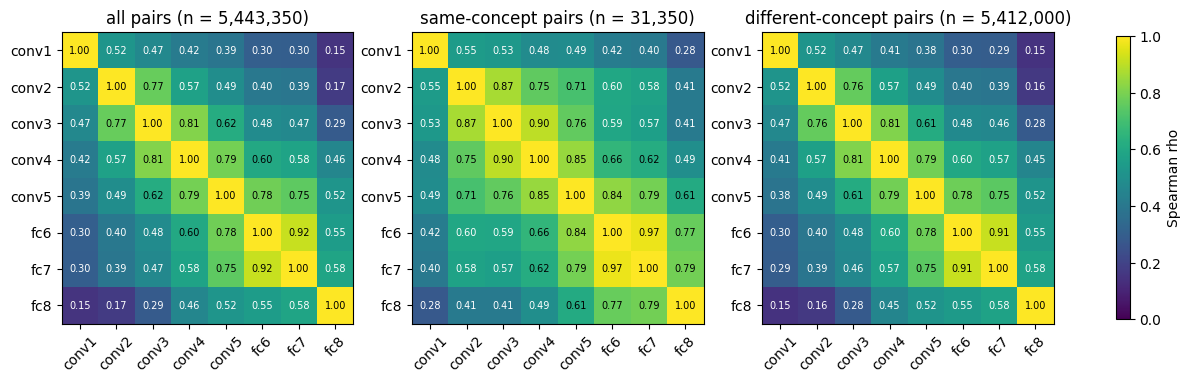

conv2 vs fc7, all pairs: rho = 0.39
conv2 vs fc7, same-concept pairs: rho = 0.58
conv2 vs fc7, different-concept pairs: rho = 0.39


In [22]:
def spearman_matrix(mask):
    R = np.vstack([rankdata(vec[n][mask]) for n in LAYER_NAMES])
    return np.corrcoef(R)

masks = {'all pairs': np.ones_like(same_concept),
         'same-concept pairs': same_concept,
         'different-concept pairs': ~same_concept}
corr = {k: spearman_matrix(m) for k, m in masks.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (k, M) in zip(axes, corr.items()):
    im = ax.imshow(M, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(len(LAYER_NAMES)), LAYER_NAMES, rotation=45)
    ax.set_yticks(range(len(LAYER_NAMES)), LAYER_NAMES)
    for i in range(len(LAYER_NAMES)):
        for j in range(len(LAYER_NAMES)):
            ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if M[i, j] < 0.6 else 'black')
    ax.set_title(f'{k} (n = {masks[k].sum():,})')
fig.colorbar(im, ax=axes, shrink=0.8, label='Spearman rho')
plt.savefig(OUT_DIR / 'fig3_layer_correlations.png', dpi=150, bbox_inches='tight'); plt.show()

e, l = LAYER_NAMES.index(EARLY), LAYER_NAMES.index(LATE)
for k, M in corr.items():
    print(f'{EARLY} vs {LATE}, {k}: rho = {M[e, l]:.2f}')

## 5. Design simulation

Repeated random assignments of concepts to the two conditions (15 HI concepts with 10 random exemplars each; 1 random exemplar from each of the other 150 concepts). For each draw:

- **Early–late collinearity** within each condition's own RDM.
- **Pair matching:** HI between-concept pairs and LI pairs are binned jointly on their early- and late-layer distances (10 × 10 quantile bins), and the same number of pairs is drawn from each condition per bin. After matching, the two pair sets should have the same DNN distance distribution, so any EEG difference between them cannot come from the stimuli.

The table reports how different the conditions are before and after matching (standardized mean difference, SMD; |SMD| < 0.1 is usually considered well balanced).

In [23]:
rng = np.random.default_rng(SEED)
concept_idx = {c: np.where(concepts == c)[0] for c in concept_names}
DE, DL = RDMS[EARLY], RDMS[LATE]

def spearman(a, b):
    return np.corrcoef(rankdata(a), rankdata(b))[0, 1]

def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

def draw_design():
    hi_c = rng.choice(concept_names, N_HI_CONCEPTS, replace=False)
    li_c = rng.choice(np.setdiff1d(concept_names, hi_c), N_LI_CONCEPTS, replace=False)
    hi = np.concatenate([rng.choice(concept_idx[c], N_HI_EXEMPLARS, replace=False) for c in hi_c])
    li = np.array([rng.choice(concept_idx[c]) for c in li_c])
    return hi, li

def pairs(idx):
    a, b = np.triu_indices(len(idx), 1)
    return idx[a], idx[b]

def match_pairs(e1, l1, e2, l2, n_bins=10):
    # joint quantile bins on (early, late) distance; equal draws per bin
    qe = np.quantile(np.r_[e1, e2], np.linspace(0, 1, n_bins + 1))
    ql = np.quantile(np.r_[l1, l2], np.linspace(0, 1, n_bins + 1))
    b1 = np.clip(np.searchsorted(qe, e1, 'right') - 1, 0, n_bins - 1) * n_bins + np.clip(np.searchsorted(ql, l1, 'right') - 1, 0, n_bins - 1)
    b2 = np.clip(np.searchsorted(qe, e2, 'right') - 1, 0, n_bins - 1) * n_bins + np.clip(np.searchsorted(ql, l2, 'right') - 1, 0, n_bins - 1)
    k1, k2 = [], []
    for b in np.intersect1d(b1, b2):
        i1, i2 = np.where(b1 == b)[0], np.where(b2 == b)[0]
        m = min(len(i1), len(i2))
        k1.append(rng.choice(i1, m, replace=False)); k2.append(rng.choice(i2, m, replace=False))
    return np.concatenate(k1), np.concatenate(k2)

sim = []
for s in range(N_SIMULATIONS):
    hi, li = draw_design()
    a, b = pairs(hi)
    hi_same = concepts[a] == concepts[b]
    hiE, hiL = DE[a, b], DL[a, b]
    a, b = pairs(li)
    liE, liL = DE[a, b], DL[a, b]
    hbE, hbL = hiE[~hi_same], hiL[~hi_same]            # HI between-concept pairs
    k1, k2 = match_pairs(hbE, hbL, liE, liL)
    sim.append({
        'rho HI all pairs': spearman(hiE, hiL),
        'rho HI same-concept': spearman(hiE[hi_same], hiL[hi_same]),
        'rho HI between-concept': spearman(hbE, hbL),
        'rho LI pairs': spearman(liE, liL),
        f'SMD {EARLY}: HI-all vs LI': smd(hiE, liE),
        f'SMD {LATE}: HI-all vs LI': smd(hiL, liL),
        f'SMD {EARLY}: HI-between vs LI': smd(hbE, liE),
        f'SMD {LATE}: HI-between vs LI': smd(hbL, liL),
        f'SMD {EARLY}: matched': smd(hbE[k1], liE[k2]),
        f'SMD {LATE}: matched': smd(hbL[k1], liL[k2]),
        'matched pairs per condition': len(k1),
        'rho matched HI-between': spearman(hbE[k1], hbL[k1]),
        'rho matched LI': spearman(liE[k2], liL[k2]),
    })
sim = pd.DataFrame(sim)
sim.to_csv(TABLE_DIR / 'design_simulation.csv', index=False)
sim.describe().T[['mean', 'std', 'min', 'max']].round(3)

,mean,std,min,max
rho HI all pairs,0.446,0.046,0.335,0.562
rho HI same-concept,0.571,0.070,0.361,0.768
rho HI between-concept,0.397,0.048,0.271,0.514
rho LI pairs,0.387,0.017,0.337,0.443
SMD conv2: HI-all vs LI,-0.094,0.117,-0.426,0.219
SMD fc7: HI-all vs LI,-0.201,0.062,-0.426,-0.078
SMD conv2: HI-between vs LI,-0.010,0.123,-0.352,0.283
SMD fc7: HI-between vs LI,0.001,0.090,-0.301,0.178
SMD conv2: matched,0.001,0.013,-0.054,0.033
SMD fc7: matched,-0.000,0.015,-0.042,0.030


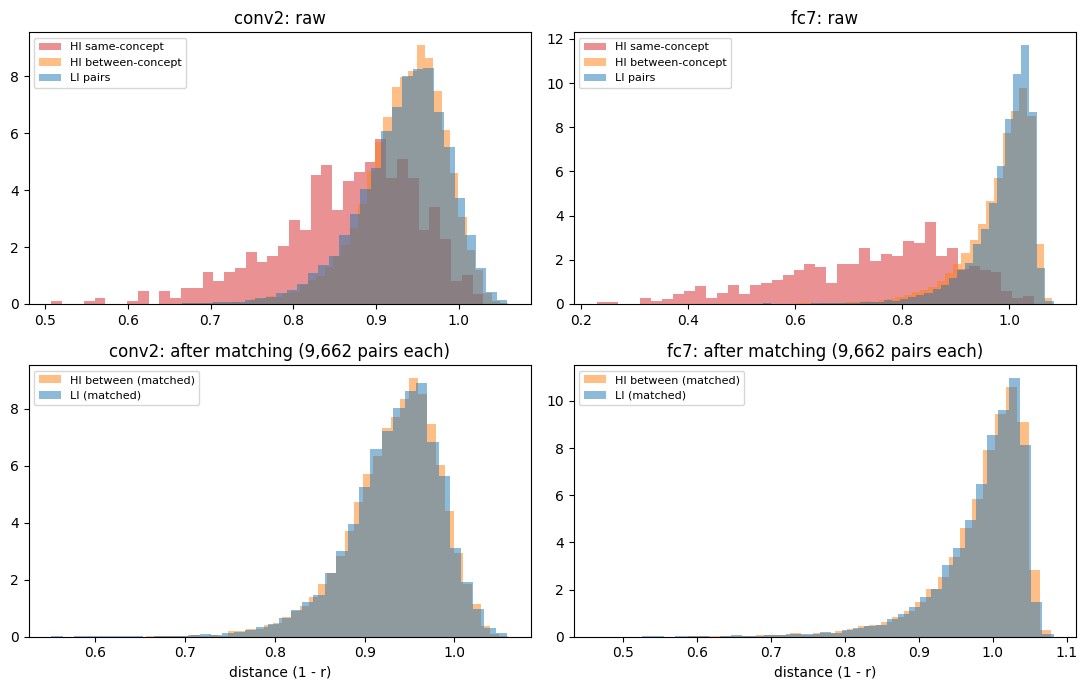

In [24]:
# Distance distributions for one example draw: raw vs. matched
hi, li = draw_design()
a, b = pairs(hi); hi_same = concepts[a] == concepts[b]
hiE, hiL = DE[a, b], DL[a, b]
a, b = pairs(li); liE, liL = DE[a, b], DL[a, b]
hbE, hbL = hiE[~hi_same], hiL[~hi_same]
k1, k2 = match_pairs(hbE, hbL, liE, liL)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, (name, hA, hB, lv) in enumerate([(EARLY, hiE, hbE, liE), (LATE, hiL, hbL, liL)]):
    ax = axes[0, col]
    ax.hist(hA[hi_same], 40, density=True, alpha=.5, label='HI same-concept', color='C3')
    ax.hist(hB, 40, density=True, alpha=.5, label='HI between-concept', color='C1')
    ax.hist(lv, 40, density=True, alpha=.5, label='LI pairs', color='C0')
    ax.set_title(f'{name}: raw'); ax.legend(fontsize=8)
    ax = axes[1, col]
    ax.hist(hB[k1], 40, density=True, alpha=.5, label='HI between (matched)', color='C1')
    ax.hist(lv[k2], 40, density=True, alpha=.5, label='LI (matched)', color='C0')
    ax.set_title(f'{name}: after matching ({len(k1):,} pairs each)'); ax.legend(fontsize=8)
    ax.set_xlabel('distance (1 - r)')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig4_design_simulation.png', dpi=150); plt.show()

## 6. Possible near-duplicates

Within-concept pairs with the smallest distances in the early layer. Very small values usually mean two photos of nearly the same object/view, which you may want to avoid pairing as target and 2AFC lure (or drop entirely).

In [25]:
pair_df = pd.DataFrame({'img_a': stim['filename'].values[iu[0][same_concept]],
                        'img_b': stim['filename'].values[iu[1][same_concept]],
                        'concept': concepts[iu[0][same_concept]],
                        f'{EARLY}_dist': vec[EARLY][same_concept],
                        f'{LATE}_dist': vec[LATE][same_concept]})
pair_df = pair_df.sort_values(f'{EARLY}_dist')
pair_df.to_csv(TABLE_DIR / 'within_concept_pairs.csv', index=False)
pair_df.head(20).round(3)

,img_a,img_b,concept,conv2_dist,fc7_dist
16404,blind_05s.jpg,blind_21s.jpg,blind,0.249,0.253
16428,blind_08s.jpg,blind_15s.jpg,blind,0.305,0.401
16503,blind_19s.jpg,blind_21s.jpg,blind,0.314,0.209
16464,blind_14s.jpg,blind_15s.jpg,blind,0.336,0.469
16475,blind_15s.jpg,blind_17s.jpg,blind,0.339,0.464
16444,blind_12s.jpg,blind_19s.jpg,blind,0.356,0.374
16399,blind_05s.jpg,blind_15s.jpg,blind,0.357,0.375
16479,blind_15s.jpg,blind_21s.jpg,blind,0.357,0.362
16402,blind_05s.jpg,blind_19s.jpg,blind,0.367,0.268
16516,blind_21s.jpg,blind_23s.jpg,blind,0.370,0.485


## 6b. Concept-to-concept distances (for building the concept sets)

Mean fc7 distance between all exemplars of two concepts. `create_stimuli_list_balanced.m` uses this to keep near-identical concepts (e.g. minivan / station_wagon) out of the same high-interference set.

In [26]:
idx = [np.where(concepts == c)[0] for c in concept_names]
Dc = np.array([[RDMS['fc7'][np.ix_(a, b)].mean() for b in idx] for a in idx])
dist_df = pd.DataFrame(Dc, index=concept_names, columns=concept_names)
dist_df.index.name = 'subcategory'
dist_df.to_csv(TABLE_DIR / 'concept_distance_fc7.csv', float_format='%.5f')
v = Dc[np.triu_indices(len(concept_names), 1)]
o = np.argsort(v)[:15]
a, b = np.triu_indices(len(concept_names), 1)
pd.DataFrame({'concept_a': concept_names[a[o]], 'concept_b': concept_names[b[o]], 'fc7_dist': v[o]}).round(3)

,concept_a,concept_b,fc7_dist
0,minivan,station_wagon,0.651
1,ambulance,firetruck,0.673
2,garbage_truck,truck,0.696
3,firetruck,trolley,0.704
4,lemon,mango,0.723
5,lemon,orange,0.726
6,forklift,garbage_truck,0.727
7,coyote,fox,0.728
8,pomegranate,strawberry,0.732
9,cucumber,zucchini,0.734


## 7. Summary

How to read the results:

- **Separation index (section 3):** should rise from early to late layers. If early layers already show a large separation, exemplars of a concept are perceptually very similar too.
- **Per-concept scatter:** concepts in the lower left (alike in both layers) are poor HI candidates. `concept_similarity.csv` has the full list.
- **Layer correlations (section 4):** the lower the `EARLY` vs `LATE` correlation (especially for same-concept pairs), the better early and late contributions can be separated in the EEG. Values near 1 would be a real problem; moderate values are normal and workable with partial correlation or variance partitioning.
- **Simulation (section 5):** the raw HI-vs-LI SMDs show how much the two image sets differ by construction. After matching, both SMDs should be close to 0. If they are, the matched between-concept comparison is a fair test.

In [27]:
print(f'Early layer: {EARLY}, late layer: {LATE}\n')
print('Separation index:', ', '.join(f'{n} {v:.2f}' for n, v in layer_summary['separation_index'].items()))
for k, M in corr.items():
    print(f'{EARLY} vs {LATE} Spearman, {k}: {M[e, l]:.2f}')
m = sim.mean()
print(f"\nSimulation ({N_SIMULATIONS} draws), mean values:")
print(f"  SMD {EARLY} HI-between vs LI: raw {m[f'SMD {EARLY}: HI-between vs LI']:.2f} -> matched {m[f'SMD {EARLY}: matched']:.2f}")
print(f"  SMD {LATE} HI-between vs LI: raw {m[f'SMD {LATE}: HI-between vs LI']:.2f} -> matched {m[f'SMD {LATE}: matched']:.2f}")
print(f"  matched pairs per condition: {m['matched pairs per condition']:.0f}")
print(f"\nTables saved in {TABLE_DIR}\nRDMs and figures saved in {OUT_DIR}")

Early layer: conv2, late layer: fc7

Separation index: conv1 0.88, conv2 1.47, conv3 1.74, conv4 2.03, conv5 3.06, fc6 3.59, fc7 4.37, fc8 1.70
conv2 vs fc7 Spearman, all pairs: 0.39
conv2 vs fc7 Spearman, same-concept pairs: 0.58
conv2 vs fc7 Spearman, different-concept pairs: 0.39

Simulation (200 draws), mean values:
  SMD conv2 HI-between vs LI: raw -0.01 -> matched 0.00
  SMD fc7 HI-between vs LI: raw 0.00 -> matched -0.00
  matched pairs per condition: 9754

Outputs saved in /Users/ekindogailkel/Memory_Interference_Experiment/Stimuli/Selection20_resized/alexnet_outputs
